# 01. Аудит исходных данных H&M

Ноутбук только читает сохранённые артефакты `hmrp audit` и `hmrp build-features` (`reports/data/`). Пересчёт: `hmrp audit --config configs/full.yaml`.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160, "display.max_columns", 30)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REP = ROOT / "reports"
def read(p): return json.loads(Path(p).read_text(encoding="utf-8"))

In [2]:
a = read(REP / "data" / "source_audit.json")
pd.DataFrame(a["loads"])[["file_role", "file_name", "load_id", "rows_read", "rows_loaded", "rows_rejected_structure", "rows_rejected_type", "size_bytes", "sha256"]]

,file_role,file_name,load_id,rows_read,rows_loaded,rows_rejected_structure,rows_rejected_type,size_bytes,sha256
0,transactions,transactions_train.csv,1,31788324,31788324,0,0,3488002253,fff5e3b35c1b26016aa0bf2231be9525bc766eed32c94f...
1,customers,customers.csv,2,1371980,1371980,0,0,207135859,abf3450c37ee1c16124e0d3379371153f5371148742efd...
2,articles,articles.csv,3,105542,105542,0,0,36127865,25f21882053517f7684ea43f524225a9481a7bb9aab9cf...


In [3]:
pd.Series(a["transactions"]).to_frame("transactions")

,transactions
n_rows,31788324
n_customers,1362281
n_articles,104547
min_date,2018-09-20
max_date,2020-09-22
n_distinct_dates,734
sum_price,884645.973961


## Цена (предоставленная шкала) и совпадающие строки

In [4]:
pr = a["price"]
pd.DataFrame({"level": pr["quantile_levels"], "price": pr["quantiles"]}).set_index("level").T.assign(n_zero=pr["n_zero"], n_negative=pr["n_negative"])

level,0.001,0.01,0.05,0.25,0.5,0.75,0.95,0.99,0.999,n_zero,n_negative
price,0.001678,0.003576,0.00761,0.015814,0.025407,0.033881,0.059305,0.10022,0.167797,0,0


In [5]:
pd.DataFrame(a["identical_rows"]).head(10)

,multiplicity,n_groups,n_rows
0,1,26269511,26269511.0
1,2,2285073,4570146.0
2,3,177237,531711.0
3,4,55412,221648.0
4,5,9259,46295.0
5,6,8181,49086.0
6,7,1733,12131.0
7,8,2132,17056.0
8,9,911,8199.0
9,10,1112,11120.0


## Динамика по дням и каналам

Text(0, 0.5, 'rows')

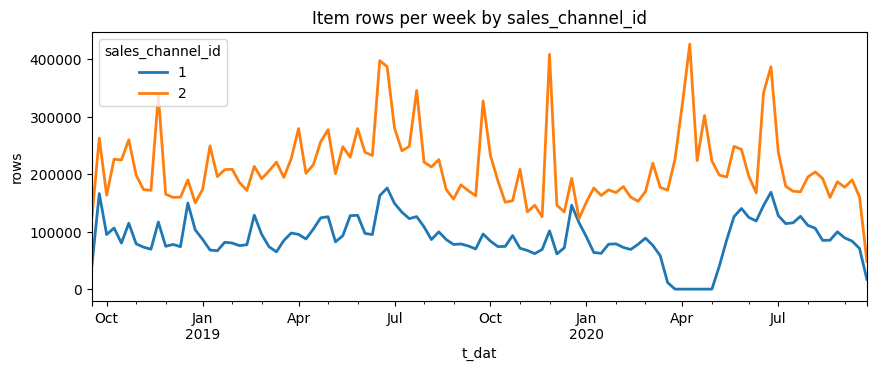

In [6]:
daily = pd.read_csv(REP / "data" / "source_daily_by_channel.csv", parse_dates=["t_dat"])
w = daily.pivot_table(index="t_dat", columns="sales_channel_id", values="n_rows", aggfunc="sum").resample("W").sum()
ax = w.plot(figsize=(10, 3.5), linewidth=2, title="Item rows per week by sales_channel_id"); ax.set_ylabel("rows")

In [7]:
m = pd.read_csv(REP / "data" / "source_monthly_by_channel.csv")
share = m.pivot_table(index="month", columns="sales_channel_id", values="n_rows", aggfunc="sum")
(share.div(share.sum(axis=1), axis=0) * 100).round(1)

sales_channel_id,1,2
month,,
2018-09-01,34.9,65.1
2018-10-01,30.3,69.7
2018-11-01,28.3,71.7
2018-12-01,38.5,61.5
2019-01-01,26.2,73.8
2019-02-01,32.6,67.4
2019-03-01,28.1,71.9
2019-04-01,30.0,70.0
2019-05-01,31.5,68.5


## Покрытие ключей и проверки JOIN

In [8]:
pd.DataFrame(a["coverage"]).T

,n_tx_customers,n_not_in_customers_csv,n_tx_articles,n_not_in_articles_csv
customers,1362281.0,0.0,NaN,NaN
articles,NaN,NaN,104547.0,0.0


In [9]:
pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk not in ("dim_key",)} for k, v in a["join_checks"].items()}).T

,fact,dim,key,measure,fact_rows,fact_sum,joined_rows,joined_sum,n_unmatched,rows_preserved,sum_preserved,status,seconds
transactions_to_articles,raw.transactions__load_1,raw.articles__load_3,article_id,price,31788324,884645.974044,31788324,884645.974043,0,True,True,passed,1.38
transactions_to_customers,raw.transactions__load_1,raw.customers__load_2,customer_id,price,31788324,884645.974044,31788324,884645.974043,0,True,True,passed,2.11


In [10]:
read(REP / "data" / "join_trap_demo.json")  # demonstration on synthetic rows, not an H&M finding

{'kind': 'demonstration_on_synthetic_data',
 'fact_rows': 4,
 'fact_sum_price': 0.07,
 'customer_days': 2,
 'unchecked_join_rows': 6,
 'unchecked_join_sum_price': 0.12,
 'guard_on_duplicate_dim': "rejected: pg_temp.demo_articles_dup.article_id is not a unique non-null key: {'n_rows': 3, 'n_distinct': 2, 'n_null': 0}",
 'corrected_join': {'fact_rows': 4,
  'joined_rows': 4,
  'fact_sum': 0.07,
  'joined_sum': 0.07,
  'n_unmatched': 0,
  'status': 'passed'}}

## Клиентская витрина (full)

In [11]:
idx = read(REP / "runs" / "index.json")
run = read(REP / "runs" / idx["full"] / "selection_decision.json")
ds = read(REP / "data" / run["dataset_id"] / "dataset_summary.json")
pd.DataFrame(ds["cohort_by_cutoff"])

,cutoff_date,role,n_rows,n_customers,n_positive,prevalence
0,2019-01-02,development,528769,528769,164115,0.310372
1,2019-02-01,development,512044,512044,162163,0.316697
2,2019-03-03,development,504320,504320,160161,0.317578
3,2019-04-02,development,495891,495891,176000,0.354917
4,2019-05-02,development,504259,504259,177223,0.351452
5,2019-06-01,development,505527,505527,204646,0.404817
6,2019-07-01,development,540233,540233,204928,0.379333
7,2019-07-31,development,553251,553251,170643,0.308437
8,2019-08-30,development,538439,538439,175335,0.325636
9,2019-09-29,development,508783,508783,171362,0.336808


In [12]:
pd.Series(ds["checks"]["customer_day_reconciliation"]).to_frame("value")

,value
raw_rows,31788324
raw_sum_price,884645.974043
day_rows,31788324
day_sum_price,884645.974051
n_customer_days,9080179
n_customers_with_purchases,1362281
rows_match,True
sum_match_rel_1e-9,True


In [13]:
pd.Series(ds["purchase_days_per_customer"]["histogram_capped_50"]).head(15)

1     447973
2     183116
3     113869
4      83255
5      65301
6      53964
7      46077
8      39569
9      34355
10     29817
11     26869
12     23700
13     20937
14     18625
15     16807
dtype: int64

In [14]:
pd.Series({k: v for k, v in ds["coverage"].items() if k != "missing_dates"}).to_frame("coverage")

,coverage
min_date,2018-09-20
max_date,2020-09-22
n_dates_with_rows,734
n_calendar_days,734
low_volume_days_ratio_below_0_5,"{'2018-12-25': 0.431, '2019-12-25': 0.414, '20..."
last_day_rows,32866
last_day_ratio_to_trailing_28d_median,0.850228
observation_end_exclusive,2020-09-23
observation_end_decision,max(t_dat) + 1 day: no missing dates and the l...
truncation_ratio_threshold,0.5
